Real reference: 6,233 images | /kaggle/working/nd_iris_project/notebook02_preprocessing/images_224
GAN: 38 images | /kaggle/working/nd_iris_project/notebook06_gan_augmentation/generated_samples
Diffusion: 17 images | /kaggle/working/nd_iris_project/notebook07_diffusion_training/generated_samples
Traditional augmentation: 12,466 images | /kaggle/working/nd_iris_project/notebook05_traditional_augmentation/augmented_images


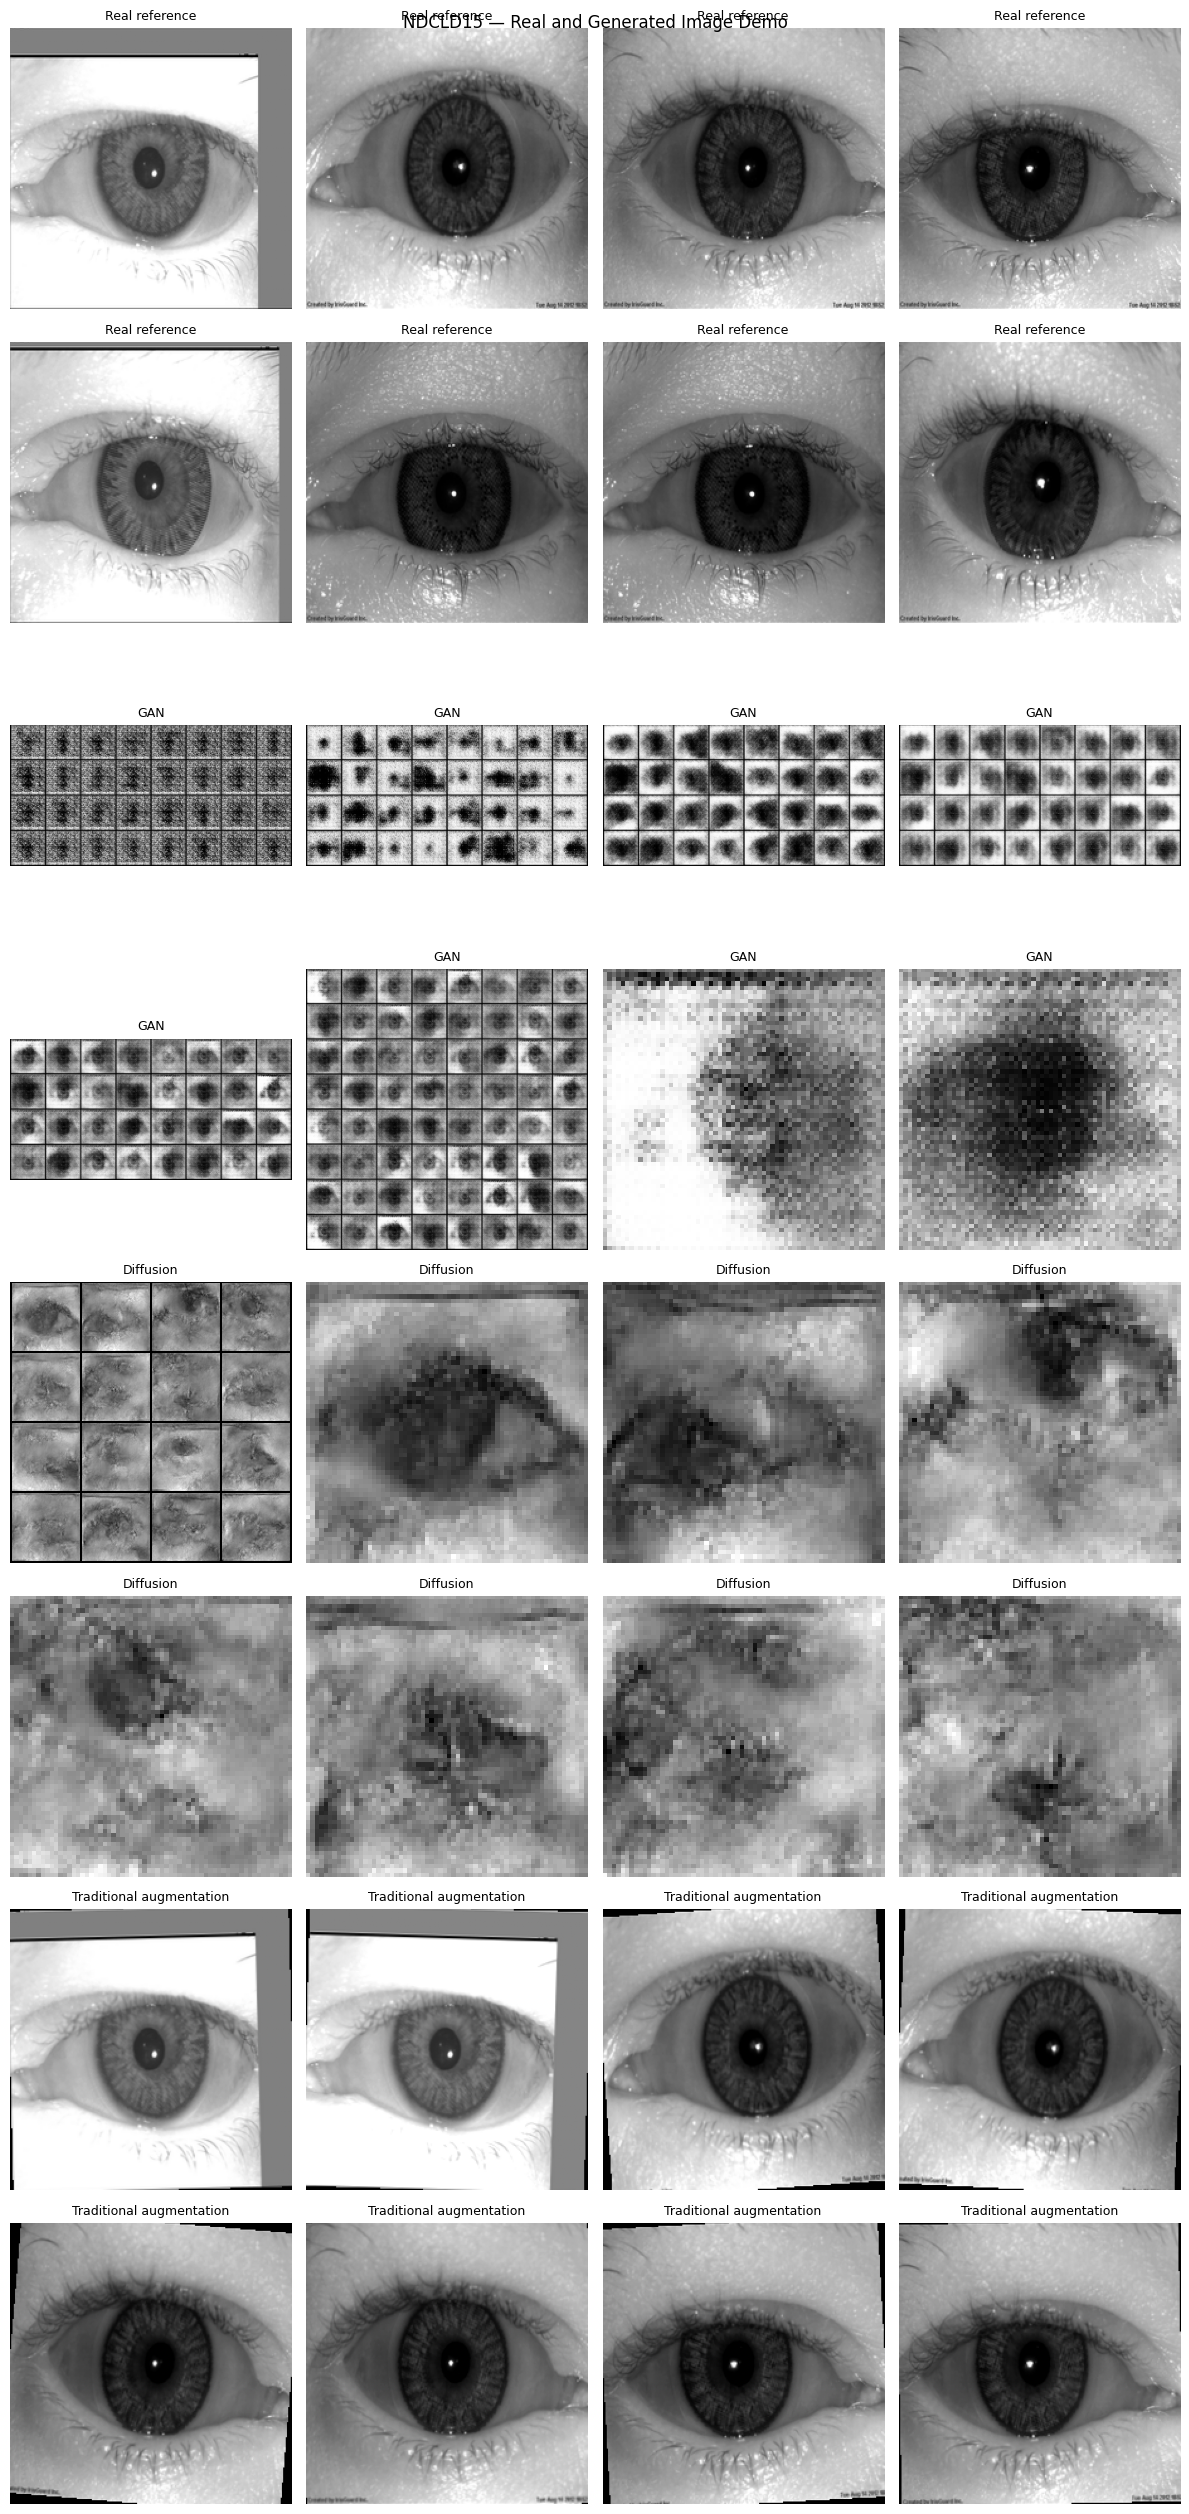


NOTEBOOK 15 — FINAL DEPLOYMENT AND DEMO COMPLETED
Output folder: /kaggle/working/nd_iris_project/notebook15_final_deployment
ZIP: /kaggle/working/nd_iris_project/ND_Iris_Notebook15_Results.zip
ZIP files: 39
ZIP integrity: PASSED
Gallery images: 32
Run summary: /kaggle/working/nd_iris_project/notebook15_final_deployment/reports/Notebook15_Run_Summary.json
Final report: /kaggle/working/nd_iris_project/notebook15_final_deployment/reports/Final_Project_Report.md
Elapsed seconds: 6.67


,Image group,Images discovered
0,Real reference,6233
1,GAN,38
2,Diffusion,17
3,Traditional augmentation,12466


,notebook,result,status,limitation
0,04 - Baseline Recognition,30.18% test accuracy,Exploratory,Filename-derived proxy labels; not verified re...
1,06 - GAN Augmentation,5 training epochs; 38 generated samples evalua...,Completed,Visual/statistical results do not prove realis...
2,07 - Diffusion Training,5 training epochs; noise-prediction MSE decrea...,Completed,Unconditional generation; no verified identity...
3,10 - Recognition with Augmented Data,36.4905% test accuracy,Exploratory,Real images only; not a controlled augmentatio...
4,12 - Membership Inference,49.8667% accuracy; AUC 0.49994,Simulation,Random membership assignment; not a real train...
5,13 - Privacy Leakage,55 generated samples screened; zero exact matc...,Exploratory,Limited reference sample and similarity metrics


# NDCLD15 Ocular Image Project — Final Report

## Project status

The 15-notebook exploratory pipeline has reached its final deployment and demo stage.
This notebook creates a small gallery, artifact manifests, an experiment summary,
and a portable ZIP package from the files currently available in the Kaggle session.

## Available image assets

| Group | Images discovered |
|---|---:|
| Real reference | 6233 |
| GAN | 38 |
| Diffusion | 17 |
| Traditional augmentation | 12466 |

## Key experimental results

- Notebook 04 baseline proxy-label test accuracy: 30.18%.
- Notebook 10 proxy-label test accuracy: 36.4905%.
- Notebook 07 diffusion noise-prediction MSE decreased from 0.204892 to 0.074839 over five epochs.
- Notebook 12 simulated membership-inference accuracy was 49.8667%, with ROC-AUC 0.49994.
- Notebook 13 screened 38 GAN and 17 diffusion samples and reported no exact matches in the sampled real reference set.

## Essential limitations

The downloaded dataset did not include verified ground-truth annotations in the available files.
Filename-derived labels were used for exploratory recognition experiments. Therefore,
the reported recognition accuracy is not verified iris-identity recognition or
contact-lens classification accuracy.

Notebook 10 trained on real images rather than on a controlled augmented training set,
so the improvement over Notebook 04 cannot be attributed to augmentation. Image-statistic
comparisons are descriptive and do not establish perceptual realism, semantic diversity,
identity preservation, or clinical validity.

The membership-inference experiment used randomly assigned membership labels and is a
simulation, not evidence of resistance to a real attack. The generated-to-real similarity
screening covered only a limited sample and does not constitute a formal privacy guarantee.

## Deployment scope

This package is an offline demonstration and research artifact bundle. It does not provide
a production biometric service, verified identity predictions, or clinical decision support.

## Files created

- `demo/`: selected image gallery files.
- `assets/`: demo visualization.
- `reports/demo_gallery_manifest.csv`: gallery file manifest.
- `reports/experiment_summary.csv`: summary of key experiments.
- `reports/previous_conclusion_inventory.csv`: discovered prior conclusion files.
- `Final_Project_Report.md`: this report.

## Conclusion

The project demonstrates an end-to-end exploratory workflow for ocular-image preparation,
quality assessment, baseline proxy-label experiments, traditional augmentation, GAN and
diffusion image generation, image-statistic comparison, and preliminary similarity/privacy
screening. Verified annotations, controlled recognition experiments, and more rigorous
evaluation are necessary before making claims about biometric performance, augmentation
benefit, or privacy protection.


In [20]:

from pathlib import Path
import json
import time
import shutil
import zipfile
import hashlib
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display, Markdown

# ============================================================
# NOTEBOOK 15 — FINAL DEPLOYMENT AND DEMO
# ============================================================
START = time.time()
PROJECT = Path("/kaggle/working/nd_iris_project")
OUT = PROJECT / "notebook15_final_deployment"
DEMO = OUT / "demo"
REPORTS = OUT / "reports"
ASSETS = OUT / "assets"

for p in [DEMO, REPORTS, ASSETS]:
    p.mkdir(parents=True, exist_ok=True)

random.seed(42)
np.random.seed(42)

assert PROJECT.exists(), f"Project directory not found: {PROJECT}"

# ------------------------------------------------------------
# 1. Discover existing image folders
# ------------------------------------------------------------
CANDIDATES = {
    "Real reference": [
        PROJECT / "notebook02_preprocessing/images_224",
        PROJECT / "notebook09_dataset_augmentation/dataset/real",
    ],
    "GAN": [
        PROJECT / "notebook06_gan_augmentation/generated_samples",
        PROJECT / "notebook09_dataset_augmentation/dataset/gan",
    ],
    "Diffusion": [
        PROJECT / "notebook07_diffusion_training/generated_samples",
        PROJECT / "notebook09_dataset_augmentation/dataset/diffusion",
    ],
    "Traditional augmentation": [
        PROJECT / "notebook05_traditional_augmentation/augmented_images",
        PROJECT / "notebook09_dataset_augmentation/dataset/traditional",
    ],
}

IMAGE_EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

def find_images(candidates):
    for folder in candidates:
        if folder.exists():
            files = sorted(
                p for p in folder.rglob("*")
                if p.is_file() and p.suffix.lower() in IMAGE_EXTS
            )
            if files:
                return folder, files
    return None, []

sources = {}
for name, candidates in CANDIDATES.items():
    folder, files = find_images(candidates)
    sources[name] = {"folder": folder, "files": files}
    print(f"{name}: {len(files):,} images | {folder}")

# ------------------------------------------------------------
# 2. Build a portable demo gallery
# ------------------------------------------------------------
gallery_rows = []
gallery_images = []

for group, info in sources.items():
    files = info["files"]
    if not files:
        continue

    # Keep the gallery small and reproducible.
    chosen = files[:min(8, len(files))]
    for idx, src in enumerate(chosen, start=1):
        try:
            with Image.open(src) as im:
                im = ImageOps.grayscale(im)
                im.thumbnail((320, 320))
                dst = DEMO / (
                    group.lower().replace(" ", "_") +
                    f"_{idx:02d}.png"
                )
                im.save(dst, format="PNG")
                gallery_rows.append({
                    "group": group,
                    "source_path": str(src),
                    "demo_file": str(dst.relative_to(OUT)),
                    "width": im.width,
                    "height": im.height,
                })
                gallery_images.append((group, dst))
        except Exception as e:
            print(f"Gallery warning: {src.name}: {e}")

gallery_df = pd.DataFrame(gallery_rows)
gallery_df.to_csv(REPORTS / "demo_gallery_manifest.csv", index=False)

# Display gallery
if gallery_images:
    ncols = 4
    nrows = int(np.ceil(len(gallery_images) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(12, 3.2 * nrows)
    )
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, (group, path) in zip(axes, gallery_images):
        with Image.open(path) as im:
            ax.imshow(im, cmap="gray")
        ax.set_title(group, fontsize=9)
        ax.axis("off")

    plt.suptitle("NDCLD15 — Real and Generated Image Demo")
    plt.tight_layout()
    gallery_plot = ASSETS / "final_demo_gallery.png"
    plt.savefig(gallery_plot, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
else:
    print("No images found for gallery; verify source folders.")

# ------------------------------------------------------------
# 3. Collect experiment summaries from previous notebooks
# ------------------------------------------------------------
summary_rows = []

known_results = [
    {
        "notebook": "04 - Baseline Recognition",
        "result": "30.18% test accuracy",
        "status": "Exploratory",
        "limitation": "Filename-derived proxy labels; not verified recognition",
    },
    {
        "notebook": "06 - GAN Augmentation",
        "result": "5 training epochs; 38 generated samples evaluated later",
        "status": "Completed",
        "limitation": "Visual/statistical results do not prove realism or utility",
    },
    {
        "notebook": "07 - Diffusion Training",
        "result": "5 training epochs; noise-prediction MSE decreased from 0.204892 to 0.074839",
        "status": "Completed",
        "limitation": "Unconditional generation; no verified identity labels",
    },
    {
        "notebook": "10 - Recognition with Augmented Data",
        "result": "36.4905% test accuracy",
        "status": "Exploratory",
        "limitation": "Real images only; not a controlled augmentation experiment",
    },
    {
        "notebook": "12 - Membership Inference",
        "result": "49.8667% accuracy; AUC 0.49994",
        "status": "Simulation",
        "limitation": "Random membership assignment; not a real trained-model attack",
    },
    {
        "notebook": "13 - Privacy Leakage",
        "result": "55 generated samples screened; zero exact matches reported",
        "status": "Exploratory",
        "limitation": "Limited reference sample and similarity metrics",
    },
]

summary_rows.extend(known_results)

# Read available conclusion files as an artifact inventory.
conclusions = []
for path in sorted(PROJECT.glob("notebook*/**/*Conclusion*.md")):
    conclusions.append({
        "notebook_folder": str(path.parent.relative_to(PROJECT)),
        "conclusion_file": str(path.relative_to(PROJECT)),
        "size_bytes": path.stat().st_size,
    })

pd.DataFrame(summary_rows).to_csv(
    REPORTS / "experiment_summary.csv", index=False
)
pd.DataFrame(conclusions).to_csv(
    REPORTS / "previous_conclusion_inventory.csv", index=False
)

# ------------------------------------------------------------
# 4. Create final project report
# ------------------------------------------------------------
image_counts = {
    name: len(info["files"]) for name, info in sources.items()
}
report = f"""# NDCLD15 Ocular Image Project — Final Report

## Project status

The 15-notebook exploratory pipeline has reached its final deployment and demo stage.
This notebook creates a small gallery, artifact manifests, an experiment summary,
and a portable ZIP package from the files currently available in the Kaggle session.

## Available image assets

| Group | Images discovered |
|---|---:|
""" + "\n".join(
    f"| {name} | {count} |"
    for name, count in image_counts.items()
) + f"""

## Key experimental results

- Notebook 04 baseline proxy-label test accuracy: 30.18%.
- Notebook 10 proxy-label test accuracy: 36.4905%.
- Notebook 07 diffusion noise-prediction MSE decreased from 0.204892 to 0.074839 over five epochs.
- Notebook 12 simulated membership-inference accuracy was 49.8667%, with ROC-AUC 0.49994.
- Notebook 13 screened 38 GAN and 17 diffusion samples and reported no exact matches in the sampled real reference set.

## Essential limitations

The downloaded dataset did not include verified ground-truth annotations in the available files.
Filename-derived labels were used for exploratory recognition experiments. Therefore,
the reported recognition accuracy is not verified iris-identity recognition or
contact-lens classification accuracy.

Notebook 10 trained on real images rather than on a controlled augmented training set,
so the improvement over Notebook 04 cannot be attributed to augmentation. Image-statistic
comparisons are descriptive and do not establish perceptual realism, semantic diversity,
identity preservation, or clinical validity.

The membership-inference experiment used randomly assigned membership labels and is a
simulation, not evidence of resistance to a real attack. The generated-to-real similarity
screening covered only a limited sample and does not constitute a formal privacy guarantee.

## Deployment scope

This package is an offline demonstration and research artifact bundle. It does not provide
a production biometric service, verified identity predictions, or clinical decision support.

## Files created

- `demo/`: selected image gallery files.
- `assets/`: demo visualization.
- `reports/demo_gallery_manifest.csv`: gallery file manifest.
- `reports/experiment_summary.csv`: summary of key experiments.
- `reports/previous_conclusion_inventory.csv`: discovered prior conclusion files.
- `Final_Project_Report.md`: this report.

## Conclusion

The project demonstrates an end-to-end exploratory workflow for ocular-image preparation,
quality assessment, baseline proxy-label experiments, traditional augmentation, GAN and
diffusion image generation, image-statistic comparison, and preliminary similarity/privacy
screening. Verified annotations, controlled recognition experiments, and more rigorous
evaluation are necessary before making claims about biometric performance, augmentation
benefit, or privacy protection.
"""
(REPORTS / "Final_Project_Report.md").write_text(report, encoding="utf-8")

# ------------------------------------------------------------
# 5. Inventory existing artifacts AFTER all previous notebooks
#    have completed, excluding this notebook's own output folder.
# ------------------------------------------------------------
inventory_rows = []
for folder in sorted(PROJECT.glob("notebook*")):
    if not folder.is_dir() or folder == OUT:
        continue
    files = [p for p in folder.rglob("*") if p.is_file()]
    inventory_rows.append({
        "folder": folder.name,
        "file_count": len(files),
        "size_mb": round(sum(p.stat().st_size for p in files) / (1024**2), 3),
    })

inventory_df = pd.DataFrame(inventory_rows)
inventory_df.to_csv(REPORTS / "final_artifact_inventory.csv", index=False)

# ------------------------------------------------------------
# 6. ZIP final deployment artifacts
# ------------------------------------------------------------
ZIP_PATH = PROJECT / "ND_Iris_Notebook15_Results.zip"
if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for p in OUT.rglob("*"):
        if p.is_file() and p != ZIP_PATH:
            zf.write(p, arcname=str(p.relative_to(OUT)))

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    bad_file = zf.testzip()
    zip_count = len(zf.namelist())

assert bad_file is None, f"ZIP integrity failure: {bad_file}"

# ------------------------------------------------------------
# 7. Final status and visible report
# ------------------------------------------------------------
elapsed = round(time.time() - START, 2)
status = {
    "notebook": 15,
    "status": "COMPLETED",
    "output_folder": str(OUT),
    "zip_path": str(ZIP_PATH),
    "zip_file_count": zip_count,
    "zip_integrity": "PASSED",
    "gallery_images": len(gallery_rows),
    "image_counts": image_counts,
    "elapsed_seconds": elapsed,
    "verified_ground_truth_available": False,
}
(REPORTS / "Notebook15_Run_Summary.json").write_text(
    json.dumps(status, indent=2), encoding="utf-8"
)

# Rebuild ZIP to include run summary.
with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for p in OUT.rglob("*"):
        if p.is_file() and p != ZIP_PATH:
            zf.write(p, arcname=str(p.relative_to(OUT)))

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    bad_file = zf.testzip()
    zip_count = len(zf.namelist())
assert bad_file is None

print("\n" + "=" * 60)
print("NOTEBOOK 15 — FINAL DEPLOYMENT AND DEMO COMPLETED")
print("=" * 60)
print("Output folder:", OUT)
print("ZIP:", ZIP_PATH)
print("ZIP files:", zip_count)
print("ZIP integrity: PASSED")
print("Gallery images:", len(gallery_rows))
print("Run summary:", REPORTS / "Notebook15_Run_Summary.json")
print("Final report:", REPORTS / "Final_Project_Report.md")
print("Elapsed seconds:", elapsed)

display(pd.DataFrame([
    {"Image group": name, "Images discovered": count}
    for name, count in image_counts.items()
]))
display(pd.DataFrame(summary_rows))
display(Markdown(report))


# Notebook 15 — Final Deployment and Demo: Conclusion

## 1. Objective

The objective of this notebook was to consolidate the project artifacts, create a visual gallery of real and generated ocular images, summarize the experimental findings, and prepare a portable deployment and demonstration package.

## 2. Deployment Results

The final deployment and demonstration notebook completed successfully.

- **Real reference images discovered:** 6,233
- **Traditional augmentation images discovered:** 12,466
- **GAN-generated images discovered:** 38
- **Diffusion-generated images discovered:** 17
- **Gallery images created:** 32
- **ZIP archive files:** 39
- **ZIP integrity verification:** Passed
- **Execution time:** 6.67 seconds

The notebook generated a demo gallery, an experiment summary, a previous-conclusion inventory, a final artifact inventory, a run-summary JSON file, and a final project report.

## 3. Summary of Experimental Findings

The baseline recognition experiment reported 30.18% test accuracy, while Notebook 10 reported 36.4905%. Both results used filename-derived proxy labels, and Notebook 10 trained using real images rather than a controlled augmented training set. The difference therefore does not establish an augmentation benefit or verified biometric recognition performance.

The diffusion model's noise-prediction MSE decreased from 0.204892 to 0.074839 over five training epochs. GAN and diffusion outputs displayed different image-statistic characteristics, but these measurements alone cannot establish perceptual realism or identity preservation.

The membership-inference simulation achieved 49.8667% accuracy and an ROC-AUC of 0.49994. Since membership labels were randomly assigned, this result does not establish resistance to a real privacy attack. The generated-to-real screening found no exact matches among the 55 generated images evaluated, but this limited screening is not a formal privacy guarantee.

## 4. Limitations

The downloaded dataset did not contain verified ground-truth annotations in the available files. Recognition results must therefore be treated as exploratory proxy-label results rather than verified iris-identity recognition or contact-lens classification.

The experiments do not establish a controlled improvement from generated-image augmentation, clinical validity, or privacy protection. Further work requires verified labels, controlled experiments, more comprehensive evaluation, and appropriate privacy testing.

## 5. Overall Conclusion

This project completed a 15-notebook exploratory pipeline covering dataset analysis, preprocessing, image-quality assessment, baseline classification, traditional augmentation, GAN and diffusion generation, image-quality and diversity proxies, dataset consolidation, recognition experiments, generator comparison, membership-inference simulation, privacy-leakage screening, visualization, and final deployment packaging.

The final notebook successfully created a visual demonstration and packaged its outputs into a ZIP archive whose integrity check passed.

**Final status: NOTEBOOK 15 COMPLETED — ALL 15 PROJECT NOTEBOOKS COMPLETED.**

The project provides a foundation for further ocular-image research, but verified recognition performance, augmentation effectiveness, and privacy guarantees remain unestablished.